# Chapter 3 problem set — MLPs and backpropagation in depth

| | |
| --- | --- |
| **Prerequisites** | Notebooks 13–20 |
| **Covers** | Manual backpropagation through mixed activations, an optimizer from scratch, three broken MLPs, diagnosing failed training runs from per-layer statistics, an independent diagnosis study |
| **Estimated time** | 5–7 hours |
| **Compute** | CPU, about two minutes in total |

These problems combine ideas from the whole chapter. Each has automated checks; problems 4 and 5 also ask for written analysis. Problem 5 is an independent mini-capstone: you design and write the experiment yourself. Attempt each problem before opening its hint.

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math

import torch.nn as nn
import torch.nn.functional as F

from dlcourse.data import make_spirals
from dlcourse.plotting import COLORS

X_spiral, y_spiral = make_spirals(n=200, classes=3, seed=0)  # (600, 2), (600,)

## Problem 1: Backpropagation through mixed activations

*Notebooks 10, 14, and 16.* Derive and implement the backward pass of this three-layer MLP by hand:

$$A_1 = X W_1^\top + \mathbf b_1,\ H_1 = \tanh(A_1); \quad A_2 = H_1 W_2^\top + \mathbf b_2,\ H_2 = \operatorname{relu}(A_2); \quad Z = H_2 W_3^\top + \mathbf b_3; \quad L = \operatorname{CE}(Z, \mathbf y),$$

where CE is the mean softmax cross-entropy over the batch. Write `manual_grads(X, y, params)` that returns the loss and a dictionary of gradients with the same keys and shapes as `params` (`"W1", "b1", "W2", "b2", "W3", "b3"`) — **without autograd**.

Before coding, write down for yourself:

1. $\partial L / \partial Z$ (notebook 10), with its shape;
2. how a gradient passes back through each affine layer (to its weights, its bias, and its input);
3. the elementwise factors for $\tanh$ and $\operatorname{relu}$ (notebook 16). For $\tanh$, express the derivative through the *output* $H_1$.

<details>
<summary><b>💡 Hint</b></summary>

Going backwards: `G_Z = (softmax(Z) - one_hot(y)) / N`; then `dW3 = G_Z.T @ H2`, `db3 = G_Z.sum(0)`, `G_H2 = G_Z @ W3`. Through relu: `G_A2 = G_H2 * (A2 > 0)`. Same pattern for layer 2. Through tanh: `G_A1 = G_H1 * (1 - H1**2)`. Layer 1 needs no gradient for `X`.

</details>

In [3]:
def init_params(sizes=(2, 16, 16, 3), seed=0, dtype=torch.float64):
    gen = torch.Generator().manual_seed(seed)
    params = {}
    for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:]), start=1):
        params[f"W{i}"] = torch.randn(n_out, n_in, generator=gen, dtype=dtype) * math.sqrt(2 / n_in)
        params[f"b{i}"] = 0.1 * torch.randn(n_out, generator=gen, dtype=dtype)
    return params


def forward_loss(X, y, p):
    """Reference forward pass, used by the checks."""
    H1 = torch.tanh(X @ p["W1"].T + p["b1"])
    H2 = torch.relu(H1 @ p["W2"].T + p["b2"])
    return F.cross_entropy(H2 @ p["W3"].T + p["b3"], y)

In [ ]:
def manual_grads(X, y, params):
    """Return (loss, grads) for the tanh → relu → linear MLP, computed by hand."""
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
X64, y64 = X_spiral[:64].double(), y_spiral[:64]
params = init_params()
loss, grads = manual_grads(X64, y64, params)
auto_params = {k: v.clone().requires_grad_() for k, v in params.items()}
auto_loss = forward_loss(X64, y64, auto_params)
auto_loss.backward()
check_close(loss, auto_loss.detach(), "loss", rtol=1e-12, atol=1e-12)
for name in params:
    check(name in grads, f"grads is missing {name!r}")
    check_shape(grads[name], tuple(params[name].shape), f"grads[{name!r}]")
    check_close(grads[name], auto_params[name].grad, f"grads[{name!r}]", rtol=1e-10, atol=1e-12)


class ManualMLPLoss(torch.autograd.Function):
    """Wraps manual_grads so gradcheck can compare it with finite differences."""

    @staticmethod
    def forward(ctx, X, W1, b1, W2, b2, W3, b3):
        p = dict(W1=W1, b1=b1, W2=W2, b2=b2, W3=W3, b3=b3)
        loss, g = manual_grads(X, y64, p)
        ctx.grads = [g[k] for k in ("W1", "b1", "W2", "b2", "W3", "b3")]
        return loss

    @staticmethod
    def backward(ctx, grad_output):
        return (None, *[grad_output * g for g in ctx.grads])


# Edge case: a batch of one example (N = 1), where sums over the batch are easy to get wrong.
loss1, grads1 = manual_grads(X64[:1], y64[:1], params)
auto1 = {k: v.clone().requires_grad_() for k, v in params.items()}
forward_loss(X64[:1], y64[:1], auto1).backward()
for name in params:
    check_close(grads1[name], auto1[name].grad, f"grads[{name!r}] for a single example", rtol=1e-10, atol=1e-12)

inputs = [params[k].clone().requires_grad_() for k in ("W1", "b1", "W2", "b2", "W3", "b3")]
check(torch.autograd.gradcheck(lambda *ps: ManualMLPLoss.apply(X64, *ps), inputs), "gradcheck failed")
passed("Problem 1")

## Problem 2: AdamW from scratch

*Notebook 19.* Implement `MyAdamW`, an optimizer that reproduces `torch.optim.AdamW` exactly. For each parameter $\theta$ with gradient $g$, at step $t = 1, 2, \dots$:

$$\theta \leftarrow \theta - \eta\lambda\,\theta \quad \text{(decoupled weight decay)},$$
$$m \leftarrow \beta_1 m + (1-\beta_1) g, \qquad v \leftarrow \beta_2 v + (1-\beta_2) g^2,$$
$$\hat m = \frac{m}{1 - \beta_1^t}, \qquad \hat v = \frac{v}{1-\beta_2^t}, \qquad \theta \leftarrow \theta - \eta\,\frac{\hat m}{\sqrt{\hat v} + \epsilon}.$$

Note that the decay multiplies $\theta$ directly; it never enters $m$ or $v$. That is the "decoupled" part (Loshchilov and Hutter, 2019), and it is why AdamW differs from Adam with an L2 penalty.

Your class takes an iterable of parameters, keeps per-parameter state, and provides `zero_grad()` and `step()`. The check trains two identical MLPs on the same mini-batches for 100 steps, one with your optimizer and one with PyTorch's, and compares every parameter.

<details>
<summary><b>💡 Hint</b></summary>

Store `m`, `v` (initialized with `torch.zeros_like(p)`) and the step count per parameter, for example in a dict keyed by the parameter's position. Do all updates inside `torch.no_grad()`. Skip parameters whose `.grad` is `None`. Use in-place operations such as `p.mul_(...)` and `p.sub_(...)` so the model's tensors change.

</details>

In [ ]:
class MyAdamW:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        # YOUR CODE HERE
        raise NotImplementedError

    def zero_grad(self):
        # YOUR CODE HERE
        raise NotImplementedError

    def step(self):
        # YOUR CODE HERE
        raise NotImplementedError

In [ ]:
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 3))


hyper = dict(lr=3e-3, betas=(0.85, 0.99), eps=1e-6, weight_decay=0.05)
mine, ref = make_model(0), make_model(0)
opt_mine, opt_ref = MyAdamW(mine.parameters(), **hyper), torch.optim.AdamW(ref.parameters(), **hyper)
gen = torch.Generator().manual_seed(1)
for _ in range(100):
    idx = torch.randint(0, len(X_spiral), (32,), generator=gen)
    for model, opt in ((mine, opt_mine), (ref, opt_ref)):
        opt.zero_grad()
        F.cross_entropy(model(X_spiral[idx]), y_spiral[idx]).backward()
        opt.step()
for (name, p_mine), p_ref in zip(mine.named_parameters(), ref.parameters()):
    check_close(p_mine, p_ref, f"parameter {name} after 100 steps", rtol=1e-5, atol=1e-6)
# Control: with weight_decay = 0, AdamW is exactly Adam.
mine0, ref0 = make_model(2), make_model(2)
opt_mine0 = MyAdamW(mine0.parameters(), lr=1e-2, weight_decay=0.0)
opt_ref0 = torch.optim.Adam(ref0.parameters(), lr=1e-2)
for _ in range(20):
    for model, opt in ((mine0, opt_mine0), (ref0, opt_ref0)):
        opt.zero_grad()
        F.cross_entropy(model(X_spiral), y_spiral).backward()
        opt.step()
for p_mine, p_ref in zip(mine0.parameters(), ref0.parameters()):
    check_close(p_mine, p_ref, "MyAdamW(weight_decay=0) vs torch.optim.Adam", rtol=1e-5, atol=1e-6)
passed("Problem 2")

## Problem 3: Three broken MLPs

*Notebooks 10, 13, 15, and 16.* Each builder below should produce a 2 → 64 → 64 → 3 classifier for the spirals, but each has one bug. All three train without errors. Fix each builder. The shared training function is below; the check trains each fixed model for 1000 Adam steps.

In [8]:
def train_and_score(model, steps=1000, lr=1e-2):
    """Train on the spirals with full-batch Adam; return (final loss, training accuracy)."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = F.cross_entropy(model(X_spiral), y_spiral)
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        accuracy = (model(X_spiral).argmax(dim=1) == y_spiral).float().mean().item()
    return loss.item(), accuracy

Each part is checked by one function below, applied to your fixed builder. The next cell runs the same checks on the **original buggy builders** first, to show that each check really detects its bug — a check that also passes on broken code would prove nothing.

In [9]:
EXPECTED_PARAMS = (2 * 64 + 64) + (64 * 64 + 64) + (64 * 3 + 3)


def check_3a(build):
    loss, acc = train_and_score(build())
    print(f"  final loss {loss:.4f}, accuracy {acc:.3f}")
    check(acc > 0.95, f"accuracy {acc:.3f}: the model still cannot bend its decision boundaries")


def check_3b(build):
    model = build()
    check(not any(isinstance(m, nn.Softmax) for m in model.modules()),
          "the model must output logits; F.cross_entropy applies softmax itself")
    loss, acc = train_and_score(model)
    print(f"  final loss {loss:.4f}, accuracy {acc:.3f}")
    check(loss < 0.2, f"final loss {loss:.3f}: the loss should approach zero on this training set")


def check_3c(build):
    model = build()
    n_params = sum(p.numel() for p in model.parameters())
    check(n_params == EXPECTED_PARAMS, f"the model registers {n_params} parameters, not {EXPECTED_PARAMS}")
    loss, acc = train_and_score(model)
    print(f"  final loss {loss:.4f}, accuracy {acc:.3f}")
    check(acc > 0.95, f"accuracy {acc:.3f}")


def expect_failure(check_fn, build, name):
    try:
        check_fn(build)
    except AssertionError as error:
        print(f"{name}: the check fails as it should — {error}")
    else:
        raise RuntimeError(f"{name}: the check did not detect the bug")

In [10]:
def buggy_build_a():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(2, 64), nn.Linear(64, 64), nn.Linear(64, 3))


def buggy_build_b():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 3), nn.Softmax(dim=1))


class BuggyMLPc(nn.Module):
    def __init__(self, sizes=(2, 64, 64, 3)):
        super().__init__()
        torch.manual_seed(0)
        self.hidden = [nn.Linear(a, b) for a, b in zip(sizes[:-2], sizes[1:-1])]
        self.out = nn.Linear(sizes[-2], sizes[-1])

    def forward(self, x):
        for layer in self.hidden:
            x = torch.relu(layer(x))
        return self.out(x)


def buggy_softmax_logits_only():
    """3b's bug without the structural check: train it, to show the loss criterion alone also catches it."""
    model = buggy_build_b()
    loss, acc = train_and_score(model)
    print(f"  buggy 3b trained anyway: final loss {loss:.4f}, accuracy {acc:.3f}")


expect_failure(check_3a, buggy_build_a, "3a buggy")
expect_failure(check_3b, buggy_build_b, "3b buggy")
buggy_softmax_logits_only()
expect_failure(check_3c, BuggyMLPc, "3c buggy")

  final loss 1.0481, accuracy 0.472
3a buggy: the check fails as it should — accuracy 0.472: the model still cannot bend its decision boundaries
3b buggy: the check fails as it should — the model must output logits; F.cross_entropy applies softmax itself


  buggy 3b trained anyway: final loss 0.5743, accuracy 0.978
3c buggy: the check fails as it should — the model registers 195 parameters, not 4547


### 3a. Accuracy stuck below 50%

<details>
<summary><b>💡 Hint</b></summary>

Notebook 02, section 8: what does a stack of affine maps with nothing in between compute?

</details>

In [ ]:
def build_a():
    torch.manual_seed(0)
    # Buggy version:
    #     return nn.Sequential(nn.Linear(2, 64), nn.Linear(64, 64), nn.Linear(64, 3))
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
check_3a(build_a)
passed("Problem 3a")

### 3b. High accuracy, but the loss will not go down

This model reaches high accuracy, yet its training loss levels off far above zero, and its "logits" behave strangely.

<details>
<summary><b>💡 Hint</b></summary>

`F.cross_entropy` applies log-softmax to its input itself (notebooks 10 and 17). What does the model output already look like? Print `model(X_spiral[:3])` and the row sums.

</details>

In [ ]:
def build_b():
    torch.manual_seed(0)
    # Buggy version:
    #     return nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(),
    #                          nn.Linear(64, 3), nn.Softmax(dim=1))
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
check_3b(build_b)
passed("Problem 3b")

### 3c. Only one layer learns

This custom module builds its hidden layers in a loop.

<details>
<summary><b>💡 Hint</b></summary>

Compare `sum(p.numel() for p in model.parameters())` with the number of parameters you expect. Notebook 15 explains which attributes `nn.Module` registers.

</details>

In [ ]:
class MLPc(nn.Module):
    def __init__(self, sizes=(2, 64, 64, 3)):
        super().__init__()
        torch.manual_seed(0)
        # Buggy version:
        #     self.hidden = [nn.Linear(a, b) for a, b in zip(sizes[:-2], sizes[1:-1])]
        # YOUR CODE HERE
        raise NotImplementedError
        self.out = nn.Linear(sizes[-2], sizes[-1])

    def forward(self, x):
        for layer in self.hidden:
            x = torch.relu(layer(x))
        return self.out(x)


def build_c():
    return MLPc()

In [ ]:
check_3c(build_c)
passed("Problem 3c")

## Problem 4: Diagnose two failed training runs

*Notebooks 15, 16, 18, and 19.* Two colleagues trained 8-hidden-layer MLPs (width 64) on the spirals for 1000 steps. Both runs failed:

| Run | Activation | Initialization | Optimizer | Final loss | Accuracy |
| --- | --- | --- | --- | --- | --- |
| A | ReLU | weights $\mathcal N(0, 1)$ | SGD, η = 0.01 | `nan` | 33% |
| B | sigmoid | PyTorch default | SGD, η = 0.1 | 1.0986 | about chance |

The helper below builds such a model from a configuration, and `layer_report` runs **one forward and backward pass at initialization** and records, for every hidden layer: the standard deviation of its activations, the fraction of units that are "inactive" (ReLU output exactly 0, or sigmoid output below 0.01 or above 0.99 — saturated), and the norm of its weight gradient.

In [17]:
ACTIVATIONS = {"relu": nn.ReLU, "sigmoid": nn.Sigmoid, "tanh": nn.Tanh}


def build_deep(config, depth=8, width=64, seed=0):
    torch.manual_seed(seed)
    layers, n_in = [], 2
    for _ in range(depth):
        linear = nn.Linear(n_in, width)
        if config["init"] == "normal1":
            nn.init.normal_(linear.weight, 0.0, 1.0)
        elif config["init"] == "kaiming":
            nn.init.kaiming_normal_(linear.weight, nonlinearity="relu")
            nn.init.zeros_(linear.bias)
        elif config["init"] == "xavier":
            gain = nn.init.calculate_gain(config["activation"])
            nn.init.xavier_normal_(linear.weight, gain=gain)
            nn.init.zeros_(linear.bias)
        elif config["init"] != "default":
            raise ValueError(f"unknown init {config['init']!r}")
        layers += [linear, ACTIVATIONS[config["activation"]]()]
        n_in = width
    layers.append(nn.Linear(width, 3))
    return nn.Sequential(*layers)


def train_config(config, steps=1000):
    model = build_deep(config)
    make_opt = {"sgd": torch.optim.SGD, "adam": torch.optim.Adam}[config["optimizer"]]
    optimizer = make_opt(model.parameters(), lr=config["lr"])
    for _ in range(steps):
        optimizer.zero_grad()
        loss = F.cross_entropy(model(X_spiral), y_spiral)
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        accuracy = (model(X_spiral).argmax(dim=1) == y_spiral).float().mean().item()
    return loss.item(), accuracy


def layer_report(config):
    """One forward/backward pass at initialization; per-hidden-layer statistics."""
    model = build_deep(config)
    linears = [m for m in model if isinstance(m, nn.Linear)][:-1]
    acts = [m for m in model if isinstance(m, tuple(ACTIVATIONS.values()))]
    outputs = []
    handles = [a.register_forward_hook(lambda mod, inp, out: outputs.append(out.detach())) for a in acts]
    F.cross_entropy(model(X_spiral), y_spiral).backward()
    for h in handles:
        h.remove()
    rows = []
    for layer, out in zip(linears, outputs):
        if config["activation"] == "relu":
            inactive = (out == 0).float().mean().item()
        else:
            inactive = ((out < 0.01) | (out > 0.99)).float().mean().item()
        rows.append((out.std().item(), inactive, layer.weight.grad.norm().item()))
    return rows


def show_report(config, name):
    rows = layer_report(config)
    print(f"Run {name}: {config}")
    print(" layer   activation std   inactive/saturated   weight-grad norm")
    for i, (std, inactive, gnorm) in enumerate(rows, start=1):
        print(f"{i:6d}   {std:14.3g}   {inactive:18.1%}   {gnorm:16.3g}")
    return rows


run_a = {"activation": "relu", "init": "normal1", "optimizer": "sgd", "lr": 0.01}
run_b = {"activation": "sigmoid", "init": "default", "optimizer": "sgd", "lr": 0.1}
rows_a = show_report(run_a, "A")
print()
rows_b = show_report(run_b, "B")

Run A: {'activation': 'relu', 'init': 'normal1', 'optimizer': 'sgd', 'lr': 0.01}
 layer   activation std   inactive/saturated   weight-grad norm
     1            0.398                53.0%           1.65e+04
     2             2.17                47.0%           2.38e+04
     3             12.7                46.1%           2.05e+04
     4             73.1                47.0%           2.65e+04
     5              394                51.7%           2.23e+04
     6         2.09e+03                55.1%           2.41e+04
     7         1.35e+04                48.2%           3.01e+04
     8         5.54e+04                54.0%           3.46e+04

Run B: {'activation': 'sigmoid', 'init': 'default', 'optimizer': 'sgd', 'lr': 0.1}
 layer   activation std   inactive/saturated   weight-grad norm
     1            0.116                 0.0%            1.5e-08
     2           0.0768                 0.0%           6.31e-07
     3           0.0729                 0.0%           4.35e-06
   

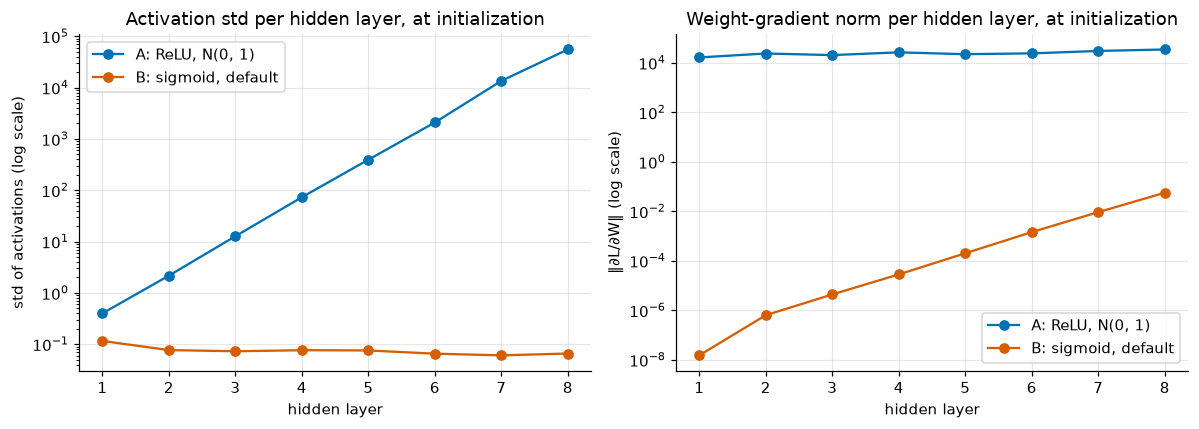

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for rows, name, color in [(rows_a, "A: ReLU, N(0, 1)", COLORS[0]), (rows_b, "B: sigmoid, default", COLORS[1])]:
    layers = range(1, len(rows) + 1)
    axes[0].semilogy(layers, [r[0] for r in rows], "o-", color=color, label=name)
    axes[1].semilogy(layers, [r[2] for r in rows], "o-", color=color, label=name)
axes[0].set_title("Activation std per hidden layer, at initialization")
axes[1].set_title("Weight-gradient norm per hidden layer, at initialization")
for ax in axes:
    ax.set_xlabel("hidden layer")
    ax.legend()
axes[0].set_ylabel("std of activations (log scale)")
axes[1].set_ylabel("‖∂L/∂W‖ (log scale)")
plt.tight_layout()
plt.show()

### 4a. Diagnose

Using the table and the plots — not trial and error — explain in the markdown cell below what goes wrong in each run, and why it leads to the final loss in the table. Then say what you would change, and why that should help, citing the relevant notebook.

*Your diagnosis:*

### 4b. Fix

Write configurations `fixed_a` and `fixed_b` — dictionaries with the keys `activation`, `init`, `optimizer`, and `lr`, using only the options `build_deep` and `train_config` support — that keep the 8×64 architecture and train to more than 95% accuracy in 1000 steps. Make each fix follow from your diagnosis: change the cause, not just the learning rate.

<details>
<summary><b>💡 Hint</b></summary>

Run A's activations grow by a constant factor per layer: match the weight scale to the activation (notebook 18). Run B's gradients shrink by a constant factor per layer toward the input: sigmoid's derivative is at most 1/4 (notebook 16), and the default weights are small. Changing the activation to one with a derivative of 1 at the origin, and initializing to match it, addresses the cause. (An optimizer that rescales each parameter's step, notebook 19, helps too, but try it and see whether it is enough.)

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
for name, config in [("A", fixed_a), ("B", fixed_b)]:
    check(set(config) == {"activation", "init", "optimizer", "lr"}, f"fixed_{name.lower()} must have exactly the keys activation, init, optimizer, lr")
    loss, accuracy = train_config(config)
    print(f"fixed {name}: final loss {loss:.4f}, accuracy {accuracy:.3f}")
    check(math.isfinite(loss) and accuracy > 0.95, f"fixed_{name.lower()} reaches only {accuracy:.3f} accuracy")
passed("Problem 4b")

## Problem 5: Independent capstone — an unfamiliar failed run

*Notebooks 03, 05, 14, 16, 19.* A colleague replaced ReLU with a home-made **softsign** activation, $s(x) = x / (1 + |x|)$, written as a custom `autograd.Function` "for speed". Their run on the spirals failed:

**Protocol (the data contract).** For a seed $s$: call `torch.manual_seed(s)`, then `build_mystery(MysterySoftsign.apply)`; train with `torch.optim.SGD(lr=0.3, momentum=0.9)` for **1500** full-batch steps of `F.cross_entropy` on `X_spiral, y_spiral`; then, under `torch.no_grad()`, record the final training loss and accuracy. The colleague's runs end with losses between about 4 and 13 and accuracy near chance, 33%.

Your job is to find the cause and *demonstrate* it, not just make the number go up. You write all the experiment code.

**Before running anything:** write down (1) at least two hypotheses for the failure that are consistent with the symptoms; (2) for each, an experiment whose result would distinguish it from the others; (3) your prediction for each experiment.

**Required pieces:**

1. **A gradient verifier.** Implement `max_grad_error(fn, x)`: for a float64 tensor `x`, compare the autograd gradient of `fn(x).sum()` with a central finite difference (notebook 03) and return the largest absolute difference as a Python float. Apply it to the mystery activation on inputs you choose — include exactly 0, negative and positive values, and large magnitudes — and to `torch.tanh` as a known-correct reference.
2. **A corrected activation**, `FixedSoftsign`, a custom `autograd.Function` with the same forward pass and a correct backward pass. It must pass `torch.autograd.gradcheck`.
3. **A one-factor experiment** with **matched updates**: every condition uses the same architecture, data, seeds, and 1500 steps, and changes **exactly one** factor from the baseline. Use at least **5 seeds** shared by all conditions, and at least three conditions:
   - condition 0: the baseline protocol above;
   - condition 1: the baseline with `FixedSoftsign` instead of `MysterySoftsign` (nothing else changed);
   - condition 2 and beyond: the alternative fix(es) your hypotheses suggest — for example, a smaller learning rate with the original activation.

   Store one row per run, `(condition, seed, final_loss, accuracy)`, in a float64 tensor `study3`, and describe each condition in a dict `conditions = {0: "...", 1: "...", ...}`. Plot every run, not only the means.

**CPU budget:** each run takes about one second; stay under about 60 runs.

In [21]:
class MysterySoftsign(torch.autograd.Function):
    """The colleague's activation: s(x) = x / (1 + |x|)."""

    @staticmethod
    def forward(ctx, x):
        out = x / (1 + x.abs())
        ctx.save_for_backward(out)
        return out

    @staticmethod
    def backward(ctx, grad_output):
        (out,) = ctx.saved_tensors
        return grad_output * (1 - out) ** 2


class Activation(nn.Module):
    def __init__(self, fn):
        super().__init__()
        self.fn = fn

    def forward(self, x):
        return self.fn(x)


def build_mystery(activation_fn):
    """2 → 64 → 64 → 3 MLP using the given activation function. Seed before calling."""
    return nn.Sequential(nn.Linear(2, 64), Activation(activation_fn), nn.Linear(64, 64),
                         Activation(activation_fn), nn.Linear(64, 3))

*Your hypotheses, distinguishing experiments, and predictions (write before running):*

<details>
<summary><b>💡 Hint</b></summary>

A diverging loss suggests a learning rate that is too large — but it is also what wrong gradients can look like. A finite-difference check separates the two: if the gradient of the activation is right, the bug is elsewhere. For the derivative of $x/(1+|x|)$, treat $x \ge 0$ and $x < 0$ separately and express the result through $|s|$.

</details>

In [ ]:
def max_grad_error(fn, x, h=1e-6):
    # YOUR CODE HERE
    raise NotImplementedError


class FixedSoftsign(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        # YOUR CODE HERE
        raise NotImplementedError

    @staticmethod
    def backward(ctx, grad_output):
        # YOUR CODE HERE
        raise NotImplementedError

In [ ]:
probe = torch.tensor([-1e3, -5.0, -1.0, -0.1, 0.0, 0.1, 1.0, 5.0, 1e3], dtype=torch.float64)
check(max_grad_error(torch.tanh, probe) < 1e-6, "max_grad_error should be tiny for torch.tanh, a correct reference")
check(max_grad_error(torch.relu, torch.tensor([-2.0, 3.0], dtype=torch.float64)) < 1e-6, "away from its kink, relu's gradient is correct")
check(max_grad_error(lambda t: MysterySoftsign.apply(t), probe) > 0.5, "your verifier should expose the mystery activation's wrong gradient on negative inputs")
# At x = 0 the second derivative of softsign jumps, so the central difference is off by about h there.
check(max_grad_error(lambda t: FixedSoftsign.apply(t), probe) < 1e-5, "FixedSoftsign's gradient disagrees with finite differences")
check_close(FixedSoftsign.apply(probe), probe / (1 + probe.abs()), "FixedSoftsign forward pass")
check(torch.autograd.gradcheck(FixedSoftsign.apply, (torch.randn(20, dtype=torch.float64, requires_grad=True),)), "gradcheck failed")
passed("Capstone gradient verification")

<details>
<summary><b>💡 Hint</b></summary>

Write one function `run(activation_fn, lr, seed)` that follows the protocol exactly and returns `(final_loss, accuracy)`; build every condition from it by changing one argument. Store rows as you go, and convert to a tensor at the end.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(isinstance(conditions, dict) and {0, 1} <= set(conditions) and len(conditions) >= 3, "describe at least conditions 0, 1, and one more in `conditions`")
check(study3.dtype == torch.float64 and study3.ndim == 2 and study3.shape[1] == 4, "study3 must be a float64 tensor with columns (condition, seed, final_loss, accuracy)")
check(set(study3[:, 0].long().tolist()) == set(conditions), "study3's conditions must match the `conditions` dict")
seed_sets = {c: set(study3[study3[:, 0] == c][:, 1].long().tolist()) for c in conditions}
first = next(iter(seed_sets.values()))
check(len(first) >= 5 and all(s == first for s in seed_sets.values()), "use the same set of at least 5 seeds in every condition")
check(len(study3) == len(conditions) * len(first), "record each (condition, seed) pair exactly once")


def reference_run(fn, seed):
    torch.manual_seed(seed)
    model = build_mystery(fn)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.3, momentum=0.9)
    for _ in range(1500):
        optimizer.zero_grad()
        F.cross_entropy(model(X_spiral), y_spiral).backward()
        optimizer.step()
    with torch.no_grad():
        logits = model(X_spiral)
        return F.cross_entropy(logits, y_spiral).item(), (logits.argmax(dim=1) == y_spiral).float().mean().item()


for condition, fn in [(0, MysterySoftsign.apply), (1, FixedSoftsign.apply)]:
    for seed in sorted(first)[:2]:
        row = study3[(study3[:, 0] == condition) & (study3[:, 1] == seed)][0]
        ref_loss, ref_acc = reference_run(fn, int(seed))
        check_close(row[2:], torch.tensor([ref_loss, ref_acc], dtype=torch.float64),
                    f"condition {condition}, seed {seed}: recorded result vs an independent run of the protocol", rtol=1e-4, atol=1e-5)
passed("Capstone experiment contract (written analysis still required)")

**Report rubric (address every item; the code checks do not grade it):**

1. **Predictions vs evidence:** for each hypothesis, what you predicted and what the measurements show.
2. **Verification:** your gradient-verifier results, including the known-correct reference, and which inputs expose the error and why.
3. **Controls and one-factor logic:** why condition 1 isolates the activation's backward pass, and what your other conditions rule in or out.
4. **Quantitative evidence across seeds:** losses and accuracies for every condition, their spread, and whether any seed contradicts the conclusion.
5. **Failure analysis:** explain the mechanism — *how* the wrong backward pass produces divergence — using the formula.
6. **Limitations and follow-up:** what this study cannot tell you, and one further experiment you would run.

*Your report:*